In [1]:
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
file = "G:/dr aamir/csa/data/spreadsheets/Complete GHG and Irrigation data 30 Sep.xls"
df = pd.read_excel(file, sheet_name="Total GHG Emission of Pakistan", index_col=0, parse_dates=True)

In [3]:
df.head(5)

,CO2 (Mte),CH4 (Mte),N2O (Mte),Total GHG (Mte),Data Status,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10
Year,,,,,,,,,,
1994-01-01,94.57,72.27,11.00,177.84,Official reported inventory,NaN,NaN,NaN,NaN,NaN
1995-01-01,99.88,75.84,12.52,188.24,Interpolated between official inventory years,NaN,NaN,NaN,NaN,NaN
1996-01-01,105.18,79.41,14.04,198.63,Interpolated between official inventory years,NaN,NaN,NaN,NaN,NaN
1997-01-01,110.48,82.98,15.56,209.02,Interpolated between official inventory years,NaN,NaN,NaN,NaN,NaN
1998-01-01,115.79,86.56,17.07,219.42,Interpolated between official inventory years,NaN,NaN,NaN,NaN,NaN


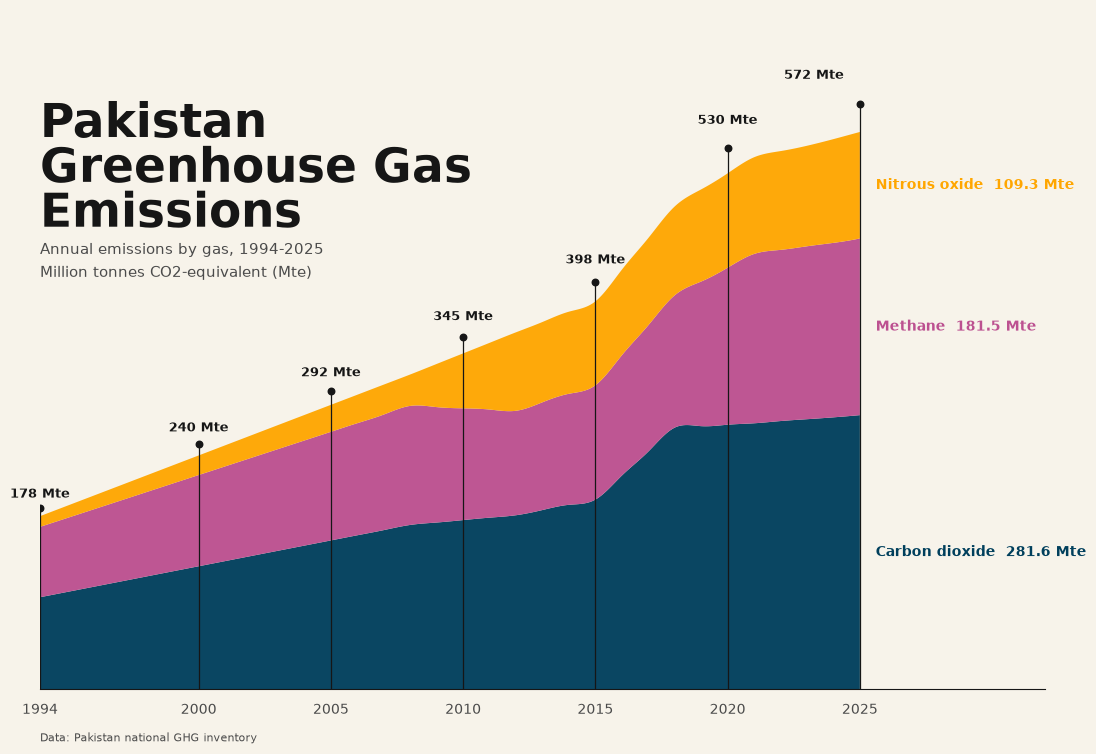

In [4]:
from scipy.interpolate import make_interp_spline

# Total GHG is already the sum of these gases, so only the components are stacked.
gas_columns = ['CO2 (Mte)', 'CH4 (Mte)', 'N2O (Mte)']
gas_labels = ['Carbon dioxide', 'Methane', 'Nitrous oxide']
colors = ['#003f5c', '#bc5090', '#ffa600']
plot_df = df[gas_columns].dropna().sort_index().copy()
years = plot_df.index.year.to_numpy()

# Smooth each component while preserving the observed annual values.
x_smooth = np.linspace(years.min(), years.max(), 400)
smooth_values = np.vstack([
    np.clip(make_interp_spline(years, plot_df[column], k=3)(x_smooth), 0, None)
    for column in gas_columns
])

fig, ax = plt.subplots(figsize=(15, 8), facecolor='#f7f3ea')
ax.set_facecolor('#f7f3ea')
ax.stackplot(x_smooth, smooth_values, colors=colors, alpha=0.96)

# Mark representative inventory years and annotate the reported totals.
available_years = set(years)
milestone_years = [year for year in [1994, 2000, 2005, 2010, 2015, 2020, years.max()] if year in available_years]
for year in milestone_years:
    row = plot_df.loc[plot_df.index.year == year].iloc[0]
    total = row[gas_columns].sum()
    ax.vlines(year, 0, total * 1.05, color='#161616', linewidth=0.9, zorder=5)
    ax.scatter(year, total * 1.05, s=22, color='#161616', zorder=6)
    x_offset = -0.6 if year == milestone_years[-1] else 0
    ha = 'right' if year == milestone_years[-1] else 'center'
    ax.text(year + x_offset, total * 1.09, f'{total:,.0f} Mte',
            ha=ha, va='bottom', fontsize=9, fontweight='bold', color='#161616')

# Label each band directly at the latest year.
latest = smooth_values[:, -1]
band_centres = np.cumsum(latest) - latest / 2
for label, value, y_pos, color in zip(gas_labels, latest, band_centres, colors):
    ax.text(years.max() + 0.6, y_pos, f'{label}  {value:,.1f} Mte',
            va='center', fontsize=10, fontweight='bold', color=color)

ax.text(years.min(), smooth_values.sum(axis=0).max() * 0.83,
        'Pakistan\nGreenhouse Gas\nEmissions',
        fontsize=34, linespacing=0.95, fontweight='bold', color='#161616')
ax.text(years.min(), smooth_values.sum(axis=0).max() * 0.74,
        f'Annual emissions by gas, {years.min()}-{years.max()}\nMillion tonnes CO2-equivalent (Mte)',
        fontsize=11, linespacing=1.5, color='#4b4b4b')

ax.set_xlim(years.min(), years.max() + 7)
ax.set_ylim(0, smooth_values.sum(axis=0).max() * 1.22)
ax.set_xticks(milestone_years)
ax.set_xlabel('')
ax.set_ylabel('')
ax.tick_params(axis='x', colors='#4b4b4b', labelsize=10, length=0, pad=10)
ax.tick_params(axis='y', left=False, labelleft=False)
for spine in ['left', 'right', 'top']:
    ax.spines[spine].set_visible(False)
ax.spines['bottom'].set_color('#161616')

fig.text(0.10, 0.035, 'Data: Pakistan national GHG inventory',
         fontsize=8, color='#4b4b4b')
plt.subplots_adjust(left=0.10, right=0.77, top=0.95, bottom=0.10)
plt.show()


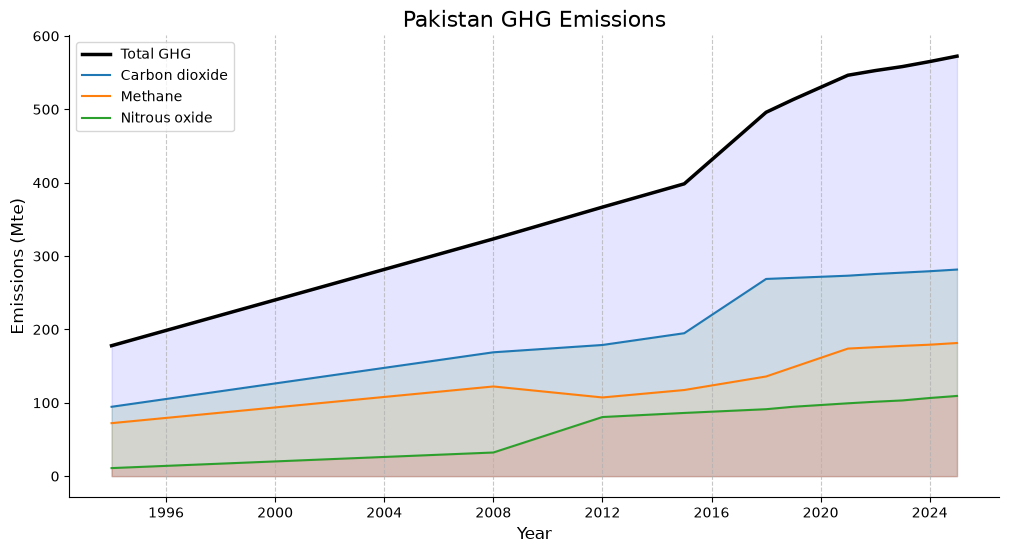

In [5]:
fig, ax = plt.subplots(figsize=(12, 6))

sns.lineplot(data=df, x=df.index, y='Total GHG (Mte)', ax=ax, label='Total GHG', color='black', linewidth=2.5)
sns.lineplot(data=df, x=df.index, y='CO2 (Mte)', ax=ax, label='Carbon dioxide')
sns.lineplot(data=df, x=df.index, y='CH4 (Mte)', ax=ax, label='Methane')
sns.lineplot(data=df, x=df.index, y='N2O (Mte)', ax=ax, label='Nitrous oxide')


ax.fill_between(df.index, df['Total GHG (Mte)'], color='blue', alpha=0.1)
ax.fill_between(df.index, df['CO2 (Mte)'], color='green', alpha=0.1)
ax.fill_between(df.index, df['CH4 (Mte)'], color='orange', alpha=0.1)
ax.fill_between(df.index, df['N2O (Mte)'], color='red', alpha=0.1)

ax.set_title('Pakistan GHG Emissions', fontsize=16)
ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Emissions (Mte)', fontsize=12)
ax.legend(fontsize=10, title_fontsize=12)


sns.despine()
ax.grid(axis='x', linestyle='--', alpha=0.7)


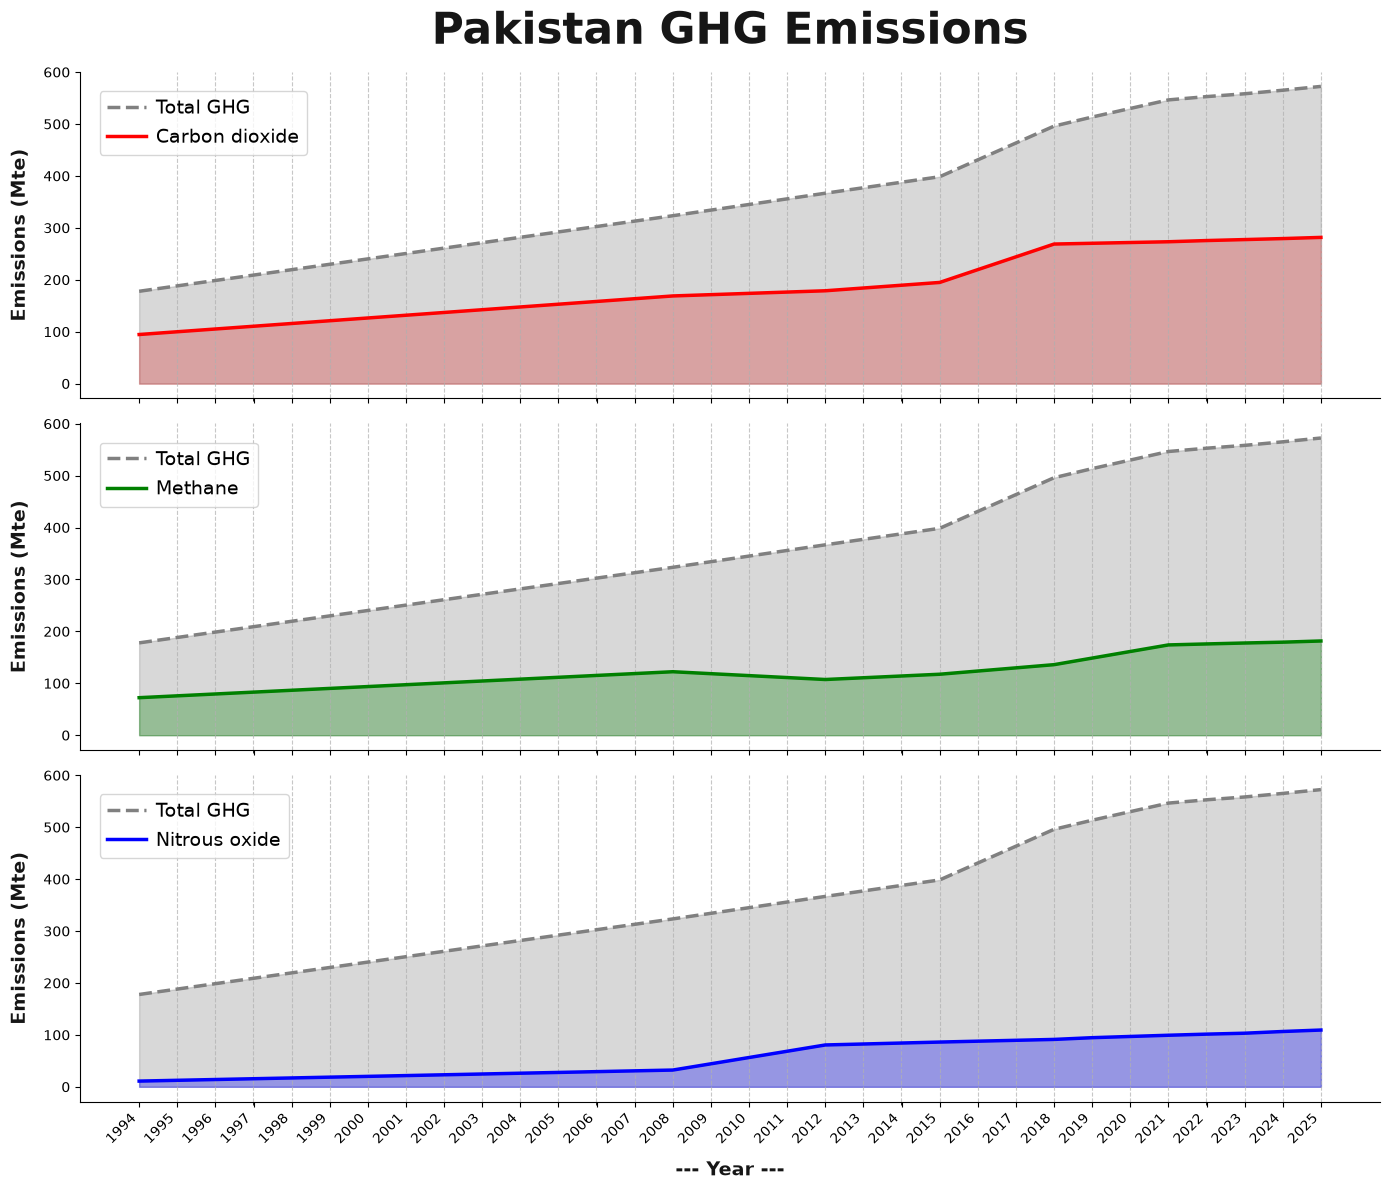

In [6]:
fig, ax = plt.subplots(figsize=(14, 12), nrows = 3, ncols = 1, sharex=True)

sns.lineplot(data=df, x=df.index, y='Total GHG (Mte)', ax=ax[0], label='Total GHG', color='gray', linewidth=2.5, linestyle='--')
sns.lineplot(data=df, x=df.index, y='CO2 (Mte)', ax=ax[0], label='Carbon dioxide', color='red', linewidth=2.5)
ax[0].fill_between(df.index, df['CO2 (Mte)'], color='red', alpha=0.3)
ax[0].fill_between(df.index, df['Total GHG (Mte)'], color='gray', alpha=0.3)

sns.lineplot(data=df, x=df.index, y='Total GHG (Mte)', ax=ax[1], label='Total GHG', color='gray', linewidth=2.5, linestyle='--')
sns.lineplot(data=df, x=df.index, y='CH4 (Mte)', ax=ax[1], label='Methane', color='green', linewidth=2.5)
ax[1].fill_between(df.index, df['Total GHG (Mte)'], color='gray', alpha=0.3)
ax[1].fill_between(df.index, df['CH4 (Mte)'], color='green', alpha=0.3)

sns.lineplot(data=df, x=df.index, y='Total GHG (Mte)', ax=ax[2], label='Total GHG', color='gray', linewidth=2.5, linestyle='--')
sns.lineplot(data=df, x=df.index, y='N2O (Mte)', ax=ax[2], label='Nitrous oxide', color='blue', linewidth=2.5)
ax[2].fill_between(df.index, df['Total GHG (Mte)'], color='gray', alpha=0.3)
ax[2].fill_between(df.index, df['N2O (Mte)'], color='blue', alpha=0.3)

# let's reformat the x-axis to show only the year
ax[2].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%Y'))

#let's add minor x-axis ticks and gridlines for better readability along with the last year which is 2025
ax[2].set_xticks(pd.date_range(start=df.index.min(), end=df.index.max(), freq='YE'), minor=True)
ax[2].grid(axis='x', which='minor', linestyle='--', alpha=0.7)
ax[1].grid(axis='x', which='minor', linestyle='--', alpha=0.7)
ax[0].grid(axis='x', which='minor', linestyle='--', alpha=0.7)

# let's reformat the x-axis to show all years from 1990 to 2025
ax[2].set_xticks(pd.date_range(start='1994-01-01', end='2025-01-01', freq='YS'))

# let's rotate the x-axis labels for better readability
for a in ax:
    a.set_xlabel('Year', fontsize=12)
    a.set_ylabel('Emissions (Mte)', fontsize=12)
    a.legend(fontsize=10, title_fontsize=12)
    for label in a.get_xticklabels():
        label.set_rotation(45)
        label.set_horizontalalignment('right')

ax[0].set_title('Pakistan GHG Emissions', fontsize=32, fontweight='bold', color='#161616', pad=20)

ax[0].legend(fontsize=14, title_fontsize=15, frameon=True, ncol=1, borderaxespad=1, columnspacing=1, handletextpad=0.5, labelspacing=0.5)
ax[1].legend(fontsize=14, title_fontsize=15, frameon=True, ncol=1, borderaxespad=1, columnspacing=1, handletextpad=0.5, labelspacing=0.5)
ax[2].legend(fontsize=14, title_fontsize=15, frameon=True, ncol=1, borderaxespad=1, columnspacing=1, handletextpad=0.5, labelspacing=0.5)

ax[2].set_xlabel('--- Year ---', fontsize=14, fontweight='bold', color='#161616', labelpad=10)
ax[2].set_ylabel('Emissions (Mte)', fontsize=14, fontweight='bold', color='#161616', labelpad=10)
ax[1].set_ylabel('Emissions (Mte)', fontsize=14, fontweight='bold', color='#161616', labelpad=10)
ax[0].set_ylabel('Emissions (Mte)', fontsize=14, fontweight='bold', color='#161616', labelpad=10)

fig.tight_layout()
sns.despine()

fig.savefig('ghg_emissions.png', dpi=300, bbox_inches='tight')

In [7]:
data = "G:/dr aamir/csa/data/spreadsheets/food security projection CSA 17 sep.xlsx"
df = pd.read_excel(data, sheet_name="csa", index_col=0, parse_dates=True)


In [8]:
df.head()

,food Demand,CSA Availability,Pop,CSA Food Gap,Traditional Avl,Traditional food gap
Year,,,,,,
2026-01-01,92.790050,82.8550,254.71,9.935050,82.8550,9.935050
2027-01-01,95.852920,83.2693,259.80,12.583620,79.8066,16.046320
2028-01-01,98.557224,83.6856,265.00,14.871624,78.1842,20.373024
2029-01-01,101.232943,84.1040,270.30,17.128943,76.3718,24.861143
2030-01-01,103.980108,84.5246,275.71,19.455508,74.4394,29.540708


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. LOAD DATA
# ============================================================

FILE_PATH = "G:/dr aamir/csa/data/spreadsheets/food security projection CSA 17 sep.xlsx"
SHEET_NAME = "csa"

df = pd.read_excel(FILE_PATH, sheet_name=SHEET_NAME)

# Inspect first if needed
print(df.columns.tolist())
print(df.head())


# ============================================================
# 2. SET COLUMN NAMES
# ============================================================
# IMPORTANT:
# Change these four names if your Excel headers differ slightly.

YEAR_COL = "Year"
DEMAND_COL = "food Demand"
CSA_COL = "CSA Availability"
TRADITIONAL_COL = "Traditional Avl"

df["Pop"].plot(ax=ax)


# Keep only required columns
plot_df = df[
    [YEAR_COL, DEMAND_COL, CSA_COL, TRADITIONAL_COL]
].copy()

# Rename internally to make plotting easier
plot_df.columns = [
    "Year",
    "Demand",
    "CSA",
    "Traditional"
]

# Convert everything to numeric
for col in ["Year", "Demand", "CSA", "Traditional"]:
    plot_df[col] = pd.to_numeric(
        plot_df[col],
        errors="coerce"
    )

# Remove invalid rows
plot_df = plot_df.dropna(
    subset=["Year", "Demand", "CSA", "Traditional"]
)

# Sort chronologically
plot_df = plot_df.sort_values("Year").reset_index(drop=True)


# ============================================================
# 3. CALCULATE STORYTELLING METRICS
# ============================================================

# Remaining deficit even after CSA
plot_df["Food_Gap"] = (
    plot_df["Demand"] - plot_df["CSA"]
)

# Improvement of CSA over traditional pathway
plot_df["CSA_Advantage"] = (
    plot_df["CSA"] - plot_df["Traditional"]
)


# Convert to arrays
years = plot_df["Year"].to_numpy()
demand = plot_df["Demand"].to_numpy()
csa = plot_df["CSA"].to_numpy()
traditional = plot_df["Traditional"].to_numpy()

food_gap = plot_df["Food_Gap"].to_numpy()
csa_advantage = plot_df["CSA_Advantage"].to_numpy()


# ============================================================
# 4. CREATE FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(16, 9.5)
)


# ============================================================
# 5. FLOATING COLUMNS
# ============================================================

# ------------------------------------------------------------
# LOWER COLUMN
# Traditional → CSA
# Shows how much availability CSA preserves/adds
# ------------------------------------------------------------

ax.bar(
    years,
    csa_advantage,
    bottom=traditional,
    width=0.58,
    alpha=0.48,
    edgecolor="none",
    label="Gap B/W CSA and Trad"
)


# ------------------------------------------------------------
# UPPER COLUMN
# CSA → Demand
# Shows remaining food deficit
# ------------------------------------------------------------

ax.bar(
    years,
    food_gap,
    bottom=csa,
    width=0.58,
    alpha=0.18,
    edgecolor="none",
    label="Gap B/W Demand and CSA"
)


# ============================================================
# 6. DRAW THE THREE MAIN LINES
# ============================================================

ax.plot(
    years,
    demand,
    linewidth=3.3,
    zorder=5,
    color="red"
)

ax.plot(
    years,
    csa,
    linewidth=3.0,
    zorder=5,
    color="green"
)

ax.plot(
    years,
    traditional,
    linewidth=2.5,
    linestyle="--",
    zorder=5,
    color="orange"
)


# ============================================================
# 7. RED CIRCLES
# Demand − CSA
# ============================================================

for x, d, c, gap in zip(
    years,
    demand,
    csa,
    food_gap
):

    # Position circle around middle of gap column
    y = c + 0.52 * (d - c)

    ax.text(
        x,
        y,
        f"{gap:.1f}",

        ha="center",
        va="center",

        fontsize=7.1,
        fontweight="bold",
        color="white",

        zorder=10,

        bbox=dict(
            boxstyle="circle,pad=0.30",
            facecolor="#C62828",
            edgecolor="white",
            linewidth=0.8
        )
    )


# ============================================================
# 8. GREEN CIRCLES
# CSA − Traditional
# ============================================================

for x, c, t, advantage in zip(
    years,
    csa,
    traditional,
    csa_advantage
):

    # Don't show zero advantage
    if advantage <= 0.05:
        continue

    # Position circle in middle of lower column
    y = t + 0.50 * (c - t)

    ax.text(
        x,
        y,
        f"{advantage:.1f}",

        ha="center",
        va="center",

        fontsize=6.7,
        fontweight="bold",
        color="white",

        zorder=11,

        bbox=dict(
            boxstyle="circle,pad=0.28",
            facecolor="#2E7D32",
            edgecolor="white",
            linewidth=0.75
        )
    )


# ============================================================
# 9. END-POINT DOTS
# ============================================================

last_year = years[-12]

"""ax.scatter(
    [last_year] * 3,
    [
        demand[-1],
        csa[-1],
        traditional[-1]
    ],
    s=[90, 80, 80],
    zorder=7
)"""


# ============================================================
# 10. DIRECT END LABELS
# ============================================================

ax.text(
    last_year + 0.02,
    142,

    f"Food DEMAND",

    va="center",
    fontsize=12,
    fontweight="bold"
)


ax.text(
    last_year + 0.38,
    csa[-1] + 0.35,

    f"CSA Farming",

    va="center",
    fontsize=11.5,
    fontweight="bold"
)


ax.text(
    last_year + 0.38,
    traditional[-1] - 0.35,

    f"Traditional Farming",

    va="center",
    fontsize=11.5,
    fontweight="bold"
)


# ============================================================
# 11. EXPLANATORY ANNOTATIONS
# ============================================================

mid_year = years[len(years) // 2]


# RED explanation
"""ax.text(
    mid_year,
    123.5,

    "RED = remaining food gap",

    fontsize=9.5,
    fontweight="bold",
    ha="center"
)


# GREEN explanation
ax.text(
    mid_year,
    66.2,

    "GREEN = CSA advantage over traditional",

    fontsize=9.5,
    fontweight="bold",
    ha="center"
)"""


# Starting-point annotation
"""ax.annotate(
    f"{int(years[0])}: no CSA advantage yet",

    xy=(
        years[0],
        csa[0]
    ),

    xytext=(
        years[0] + 2.1,
        72
    ),

    arrowprops=dict(
        arrowstyle="-",
        linewidth=1
    ),

    fontsize=9.2
)"""


# ============================================================
# 12. TITLE
# ============================================================

ax.set_title(
    "Climate Smart Agriculture & Food Security Outlook",
    fontsize=22,
    fontweight="bold"
)


# ============================================================
# 13. AXES
# ============================================================

ax.set_xlim(
    years.min() - 0.5,
    years.max() + 4.5
)


# Dynamic Y limits
minimum_y = min(traditional.min(), csa.min())
maximum_y = demand.max()

ax.set_ylim(
    minimum_y - 8,
    maximum_y + 10
)


# Show selected years only
important_years = [
    years[0],
    2030,
    2035,
    2040,
    2045,
    years[-1]
]

important_years = [
    year
    for year in important_years
    if years.min() <= year <= years.max()
]

ax.set_xticks(years)

ax.set_xticklabels([
    str(int(year))
    if year in important_years
    else ""
    for year in years
])


ax.set_ylabel(
    "Projected food demand / availability"
)


# ============================================================
# 14. GRID + SPINES
# ============================================================

ax.grid(
    axis="y",
    alpha=0.16
)

ax.set_axisbelow(True)


ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_alpha(0.30)
ax.spines["bottom"].set_alpha(0.30)


# ============================================================
# 15. LEGEND
# ============================================================

handles, labels = ax.get_legend_handles_labels()

ax.legend(
    handles[:2],
    labels[:2],
    frameon=False,
    ncols=1,
    loc="upper left",
    fontsize=14.5
)


# ============================================================
# 16. FOOTNOTE
# ============================================================

"""fig.text(
    0.12,
    0.65,

    "Red badge = Demand − CSA Availability.    \n"
    "Green badge = CSA Availability − Traditional Availability.    \n"
    "Values are shown for each projection year.    \n",

    fontsize=9.5
)"""


# ============================================================
# 17. FINAL LAYOUT
# ============================================================

plt.tight_layout()
# let's format the x-axis to show each year from 2026 to 2047 with a step of 1 years

ax.set_xticklabels(np.arange(2026, 2048, 1), rotation=45, ha='right', fontsize=10)

ax.set_facecolor('#f7f3ea')
fig.set_facecolor('#f7f3ea')

# annotate the yearly values for each line plot and make sure the annotations are not overlapping with the lines
for eachValue in [("Demand", demand), ("CSA", csa), ("Traditional", traditional)]:
    label, values = eachValue
    for x, y in zip(years, values):
        ax.annotate(f"{y:.1f}", (x, y), textcoords="offset points", xytext=(0, 5), ha='center', fontsize=8, color='black')

# let's plot the population as well

['Year', 'food Demand', 'CSA Availability', 'Pop', 'CSA Food Gap', 'Traditional Avl', 'Traditional food gap']
   Year  food Demand  CSA Availability     Pop  CSA Food Gap  Traditional Avl  \
0  2026    92.790050           82.8550  254.71      9.935050          82.8550   
1  2027    95.852920           83.2693  259.80     12.583620          79.8066   
2  2028    98.557224           83.6856  265.00     14.871624          78.1842   
3  2029   101.232943           84.1040  270.30     17.128943          76.3718   
4  2030   103.980108           84.5246  275.71     19.455508          74.4394   

   Traditional food gap  
0              9.935050  
1             16.046320  
2             20.373024  
3             24.861143  
4             29.540708  


AttributeError: 'numpy.ndarray' object has no attribute 'get_figure'

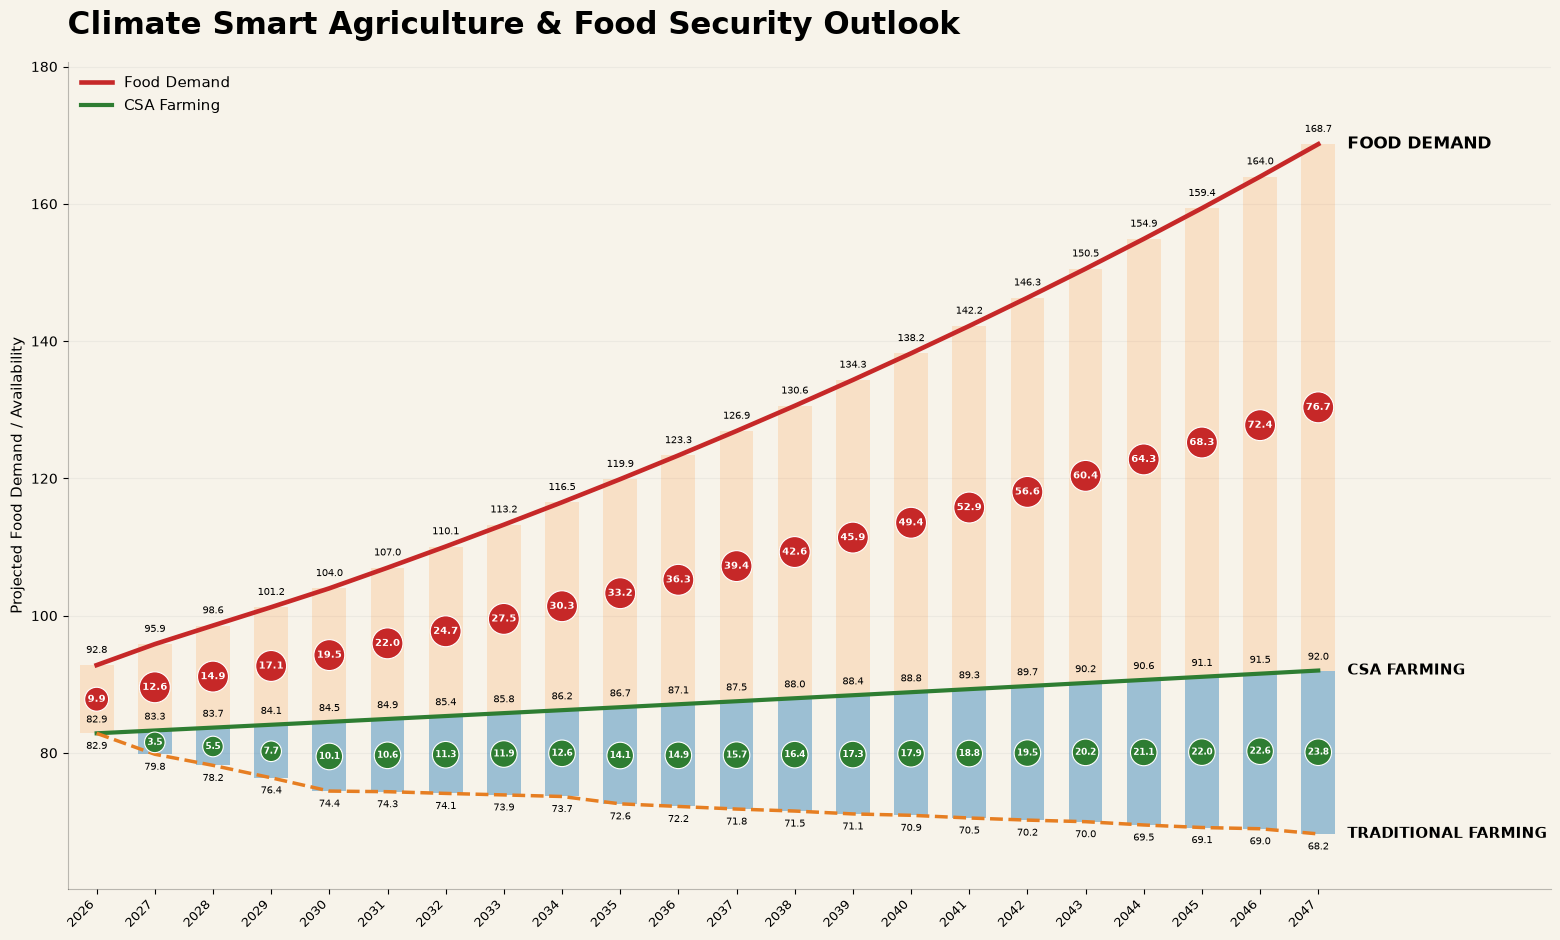

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

FILE_PATH = r"G:/dr aamir/csa/data/spreadsheets/food security projection CSA 17 sep.xlsx"
SHEET_NAME = "csa"

# Excel columns
COLUMNS = {
    "Year": "Year",
    "Demand": "food Demand",
    "CSA": "CSA Availability",
    "Traditional": "Traditional Avl",
}

# Chart text
TITLE = "Climate Smart Agriculture & Food Security Outlook"
Y_LABEL = "Projected Food Demand / Availability"

# Figure
FIGSIZE = (16, 9.5)
BACKGROUND = "#f7f3ea"
BAR_WIDTH = 0.58

# Main line colors
COLORS = {
    "Demand": "#C62828",
    "CSA": "#2E7D32",
    "Traditional": "#E67E22",

    # Annotation badges
    "FoodGap": "#C62828",
    "CSAAdvantage": "#2E7D32",
}

# Line styling
LINE_WIDTHS = {
    "Demand": 3.3,
    "CSA": 3.0,
    "Traditional": 2.5,
}

# Toggle chart elements on/off
SHOW_LINE_VALUES = True
SHOW_GAP_BADGES = True
SHOW_ADVANTAGE_BADGES = True
SHOW_LEGEND = True

# Export
SAVE_FIGURE = False
OUTPUT_FILE = "csa_food_security.png"

def load_data(file_path, sheet_name):
    """Load and prepare CSA food-security data."""

    df = pd.read_excel(
        file_path,
        sheet_name=sheet_name
    )

    # Select only columns required for this chart
    data = df[list(COLUMNS.values())].copy()

    # Standardize names
    data.columns = list(COLUMNS.keys())

    # Convert to numeric
    data = data.apply(
        pd.to_numeric,
        errors="coerce"
    )

    # Clean + sort
    data = (
        data
        .dropna()
        .sort_values("Year")
        .reset_index(drop=True)
    )

    # Derived metrics
    data["FoodGap"] = (
        data["Demand"]
        - data["CSA"]
    )

    data["CSAAdvantage"] = (
        data["CSA"]
        - data["Traditional"]
    )

    return data

def add_badges(
    ax,
    years,
    bottom,
    top,
    values,
    color,
    fontsize=7,
    skip_zero=False,
):
    """
    Add circular value badges halfway between two series.
    """

    for year, lower, upper, value in zip(
        years,
        bottom,
        top,
        values
    ):

        if skip_zero and abs(value) < 0.05:
            continue

        y = lower + 0.5 * (upper - lower)

        ax.text(
            year,
            y,
            f"{value:.1f}",
            ha="center",
            va="center",
            fontsize=fontsize,
            fontweight="bold",
            color="white",
            zorder=20,

            bbox=dict(
                boxstyle="circle,pad=0.30",
                facecolor=color,
                edgecolor="white",
                linewidth=0.8,
            )
        )


def annotate_line_values(
    ax,
    years,
    values,
    y_offset=6,
):
    """Annotate individual values along a line."""

    for year, value in zip(years, values):

        ax.annotate(
            f"{value:.1f}",
            xy=(year, value),

            xytext=(0, y_offset),
            textcoords="offset points",

            ha="center",
            va="bottom",

            fontsize=7.5,
            color="black",

            zorder=15,
        )


def style_axes(ax, fig, years):
    """Apply global chart styling."""

    # Background
    fig.patch.set_facecolor(BACKGROUND)
    ax.set_facecolor(BACKGROUND)

    # Grid
    ax.grid(
        axis="y",
        alpha=0.15,
        linewidth=0.8
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_alpha(0.25)
    ax.spines["bottom"].set_alpha(0.25)

    # X axis
    ax.set_xticks(years)

    ax.set_xticklabels(
        years.astype(int),
        rotation=45,
        ha="right",
        fontsize=9
    )

    # Y axis
    ax.set_ylabel(
        Y_LABEL,
        fontsize=11
    )

data = load_data(
    FILE_PATH,
    SHEET_NAME
)

years = data["Year"].to_numpy()

demand = data["Demand"].to_numpy()
csa = data["CSA"].to_numpy()
traditional = data["Traditional"].to_numpy()

food_gap = data["FoodGap"].to_numpy()
csa_advantage = data["CSAAdvantage"].to_numpy()

fig, ax = plt.subplots(
    figsize=FIGSIZE
)

ax.bar(
    years,
    csa_advantage,

    bottom=traditional,

    width=BAR_WIDTH,
    alpha=0.42,

    edgecolor="none",

    label="Gap B/W CSA and Traditional",
    zorder=2,
)

ax.bar(
    years,
    food_gap,

    bottom=csa,

    width=BAR_WIDTH,
    alpha=0.16,

    edgecolor="none",

    label="Gap B/W Demand and CSA",
    zorder=2,
)

ax.plot(
    years,
    demand,

    color=COLORS["Demand"],
    linewidth=LINE_WIDTHS["Demand"],

    label="Food Demand",
    zorder=5,
)


ax.plot(
    years,
    csa,

    color=COLORS["CSA"],
    linewidth=LINE_WIDTHS["CSA"],

    label="CSA Farming",
    zorder=5,
)

ax.plot(
    years,
    traditional,

    color=COLORS["Traditional"],
    linewidth=LINE_WIDTHS["Traditional"],
    linestyle="--",

    label="Traditional Farming",
    zorder=5,
)

if SHOW_GAP_BADGES:

    add_badges(
        ax=ax,

        years=years,

        bottom=csa,
        top=demand,

        values=food_gap,

        color=COLORS["FoodGap"],

        fontsize=7.1
    )

if SHOW_ADVANTAGE_BADGES:

    add_badges(
        ax=ax,

        years=years,

        bottom=traditional,
        top=csa,

        values=csa_advantage,

        color=COLORS["CSAAdvantage"],

        fontsize=6.7,

        skip_zero=True
    )

if SHOW_LINE_VALUES:

    annotate_line_values(
        ax,
        years,
        demand,
        y_offset=7
    )

    annotate_line_values(
        ax,
        years,
        csa,
        y_offset=6
    )

    annotate_line_values(
        ax,
        years,
        traditional,
        y_offset=-13
    )

label_x = years[-1] + 0.5
ax.text(
    label_x,
    demand[-1],

    "FOOD DEMAND",

    fontsize=12,
    fontweight="bold",

    va="center"
)

ax.text(
    label_x,
    csa[-1],

    "CSA FARMING",

    fontsize=11,
    fontweight="bold",

    va="center"
)

ax.text(
    label_x,
    traditional[-1],

    "TRADITIONAL FARMING",

    fontsize=11,
    fontweight="bold",

    va="center"
)

ax.set_title(
    TITLE,

    fontsize=22,
    fontweight="bold",

    loc="left",
    pad=20
)

ax.set_xlim(
    years.min() - 0.5,
    years.max() + 4
)

ax.set_ylim(
    traditional.min() - 8,
    demand.max() + 12
)

style_axes(
    ax,
    fig,
    years
)

if SHOW_LEGEND:

    handles, labels = ax.get_legend_handles_labels()
    ax.legend(
        handles[:2],
        labels[:2],

        frameon=False,

        loc="upper left",

        fontsize=11
    )

plt.tight_layout()

if SAVE_FIGURE:

    plt.savefig(
        OUTPUT_FILE,
        dpi=300,
        bbox_inches="tight",
        facecolor=fig.get_facecolor()
    )
plt.show()

In [12]:
cwr = "G:/dr aamir/csa/data/spreadsheets/CRW(efficiency) 25sep.xlsx"
df = pd.read_excel(cwr, index_col=0, parse_dates=True)
df.head()

,WAv,CWR(35%),CWR(50%),CWR(70%)
year,,,,
2026-01-01,109.0,132.0,92.4,66.0
2027-01-01,109.1,133.0,93.1,66.5
2028-01-01,109.1,135.0,94.5,67.5
2029-01-01,109.7,137.0,95.9,68.5
2030-01-01,110.3,138.0,96.6,69.0


<Axes: xlabel='year', ylabel='WAv'>

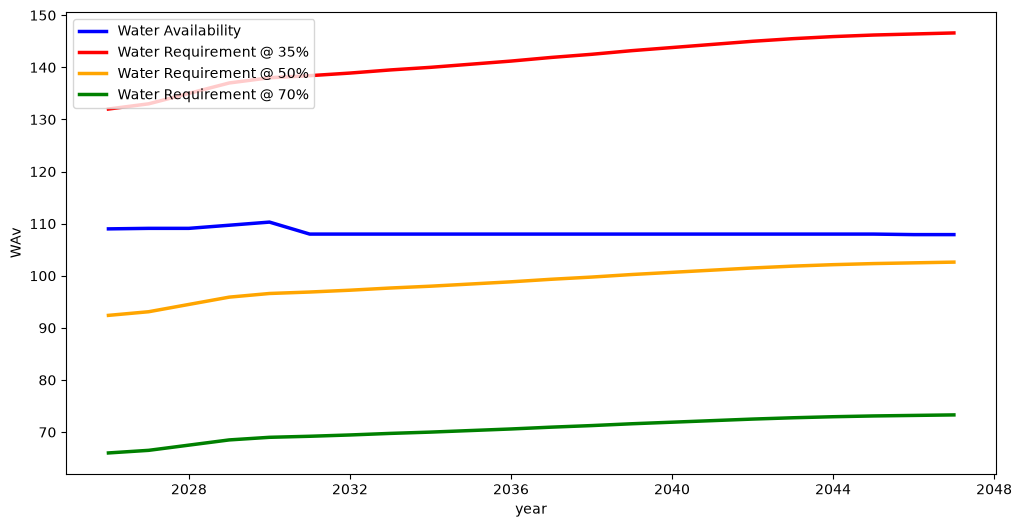

: 

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))

sns.lineplot(data=df, x=df.index, y='WAv', ax=ax, label='Water Availability', color='blue', linewidth=2.5)
sns.lineplot(data=df, x=df.index, y='CWR(35%)', ax=ax, label='Water Requirement @ 35%', color='red', linewidth=2.5)
sns.lineplot(data=df, x=df.index, y='CWR(50%)', ax=ax, label='Water Requirement @ 50%', color='orange', linewidth=2.5)
sns.lineplot(data=df, x=df.index, y='CWR(70%)', ax=ax, label='Water Requirement @ 70%', color='green', linewidth=2.5)



RAW EXCEL PREVIEW
0   year    WAv  CWR(35%)  CWR(50%)  CWR(70%)
1   2026    109       132      92.4        66
2   2027  109.1       133      93.1      66.5
3   2028  109.1       135      94.5      67.5
4   2029  109.7       137      95.9      68.5
5   2030  110.3       138      96.6        69
6   2031    108     138.4     96.88      69.2
7   2032    108     138.9     97.23     69.45
8   2033    108     139.5     97.65     69.75
9   2034    108       140        98        70
10  2035    108     140.6     98.42      70.3
11  2036    108     141.2     98.84      70.6
12  2037    108     141.9     99.33     70.95
13  2038    108     142.5     99.75     71.25
14  2039    108     143.2    100.24      71.6

Detected header row: 0

DETECTED COLUMNS
00  ->  'year'
01  ->  'WAv'
02  ->  'CWR(35%)'
03  ->  'CWR(50%)'
04  ->  'CWR(70%)'

COLUMN MAPPING
Year              -> year
Water Availability -> WAv
35% CWR           -> CWR(35%)
50% CWR           -> CWR(50%)
70% CWR           -> CWR(70%)

FINA

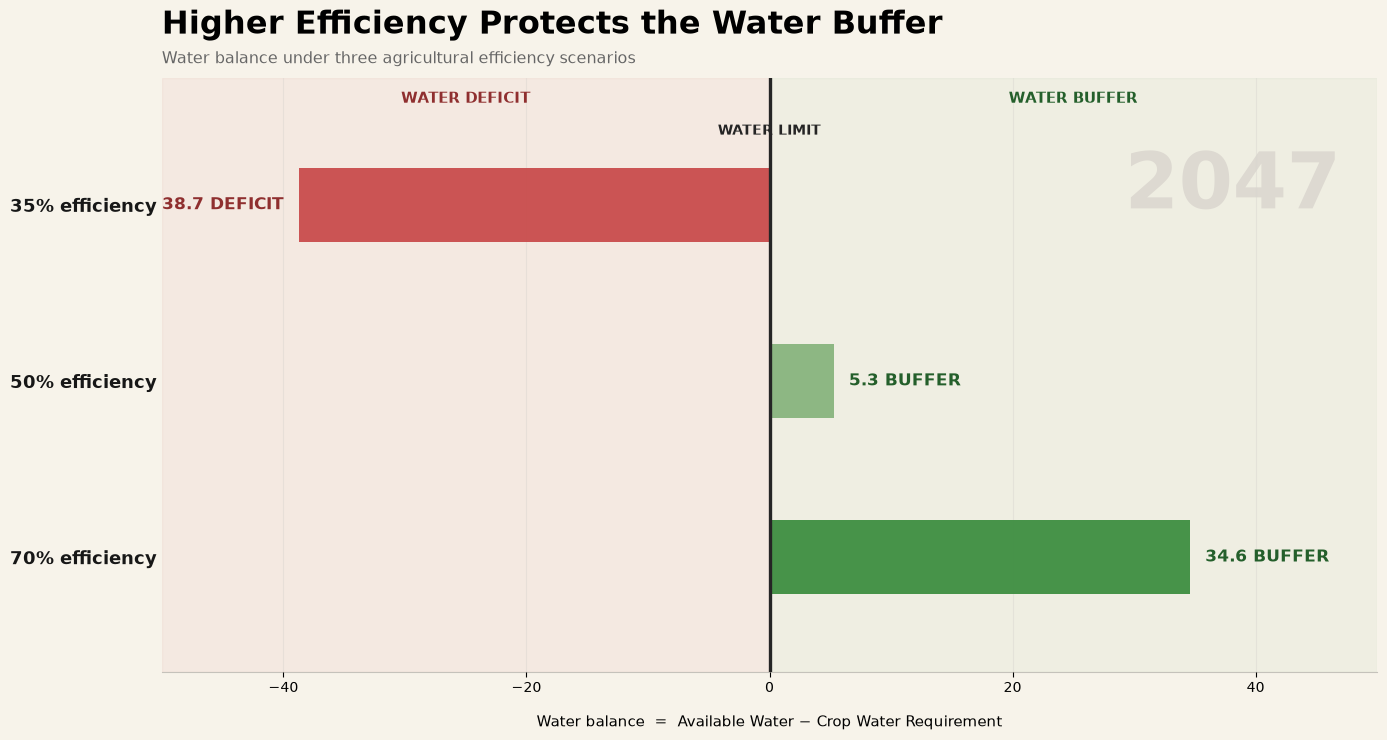

In [ ]:
# ============================================================
# ANIMATED CROP WATER BALANCE
# Water Availability vs Crop Water Requirement
#
# Story:
# LEFT  of zero = WATER DEFICIT
# RIGHT of zero = WATER BUFFER
#
# Water Balance = Water Availability - CWR
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.animation import FuncAnimation, PillowWriter
from pathlib import Path


# ============================================================
# 2. CONFIGURATION
# ============================================================

FILE_PATH = r"G:/dr aamir/csa/data/spreadsheets/CRW(efficiency) 25sep.xlsx"

# Use 0 for first sheet
SHEET_NAME = 0


# ------------------------------------------------------------
# Animation
# ------------------------------------------------------------

FPS = 10

# How long each year remains visible
FRAMES_PER_YEAR = 6

# Extra pause on 2047
FINAL_HOLD_FRAMES = 25


# ------------------------------------------------------------
# Output
# ------------------------------------------------------------

OUTPUT_GIF = "crop_water_balance_animated.gif"


# ============================================================
# 3. VISUAL SETTINGS
# ============================================================

BACKGROUND = "#F7F3EA"

COLOR_DEFICIT = "#C94C4C"

COLOR_50 = "#88B47E"

COLOR_70 = "#3E8E41"

COLOR_ZERO = "#252525"

COLOR_TEXT = "#171717"

COLOR_MUTED = "#666666"

COLOR_GRID = "#D8D5CF"


# ============================================================
# 4. INSPECT EXCEL FILE
# ============================================================

# First read without assuming any header
raw = pd.read_excel(
    FILE_PATH,
    sheet_name=SHEET_NAME,
    header=None
)


print("\nRAW EXCEL PREVIEW")
print("=" * 70)

print(
    raw.head(15).to_string(
        index=True,
        header=False
    )
)


# ============================================================
# 5. AUTOMATICALLY FIND HEADER ROW
# ============================================================

def find_header_row(dataframe, max_rows=20):
    """
    Attempts to find the row containing the actual table headers.

    Looks for terms related to:
    year, water availability, CWR, efficiency.
    """

    keywords = [
        "year",
        "wav",
        "water",
        "availability",
        "cwr",
        "35",
        "50",
        "70",
        "efficiency"
    ]

    best_row = 0
    best_score = -1

    rows_to_check = min(
        max_rows,
        len(dataframe)
    )

    for i in range(rows_to_check):

        row_text = " ".join(
            dataframe
            .iloc[i]
            .astype(str)
            .str.lower()
            .tolist()
        )

        score = sum(
            keyword in row_text
            for keyword in keywords
        )

        if score > best_score:

            best_score = score
            best_row = i


    return best_row


header_row = find_header_row(raw)


print(
    f"\nDetected header row: {header_row}"
)


# ============================================================
# 6. RELOAD USING DETECTED HEADER
# ============================================================

df = pd.read_excel(
    FILE_PATH,
    sheet_name=SHEET_NAME,
    header=header_row
)


# Clean column names
df.columns = [

    str(col)
    .replace("\n", " ")
    .replace("\r", " ")
    .strip()

    for col in df.columns
]


print("\nDETECTED COLUMNS")
print("=" * 70)

for i, col in enumerate(df.columns):

    print(
        f"{i:02d}  ->  {repr(col)}"
    )


# ============================================================
# 7. COLUMN DETECTION FUNCTION
# ============================================================

def normalize(text):

    return (
        str(text)
        .lower()
        .replace("\n", " ")
        .replace("\r", " ")
        .replace("_", " ")
        .replace("-", " ")
        .strip()
    )


def find_column(columns, groups):
    """
    groups example:

    [
        ["year"],
        ["35", "cwr"],
        ["35"]
    ]

    Returns first matching column.
    """

    normalized = {
        col: normalize(col)
        for col in columns
    }


    for required_terms in groups:

        for original, cleaned in normalized.items():

            if all(
                term.lower() in cleaned
                for term in required_terms
            ):

                return original


    return None


# ============================================================
# 8. FIND REQUIRED COLUMNS
# ============================================================

YEAR_COL = find_column(
    df.columns,
    [
        ["year"]
    ]
)


WATER_COL = find_column(
    df.columns,
    [
        ["wav"],
        ["water", "availability"],
        ["water", "available"],
        ["availability"]
    ]
)


CWR_35_COL = find_column(
    df.columns,
    [
        ["35", "cwr"],
        ["cwr", "35"],
        ["35", "eff"],
        ["35"]
    ]
)


CWR_50_COL = find_column(
    df.columns,
    [
        ["50", "cwr"],
        ["cwr", "50"],
        ["50", "eff"],
        ["50"]
    ]
)


CWR_70_COL = find_column(
    df.columns,
    [
        ["70", "cwr"],
        ["cwr", "70"],
        ["70", "eff"],
        ["70"]
    ]
)


# ============================================================
# 9. REPORT DETECTED MAPPING
# ============================================================

print("\nCOLUMN MAPPING")
print("=" * 70)

print(
    f"Year              -> {YEAR_COL}"
)

print(
    f"Water Availability -> {WATER_COL}"
)

print(
    f"35% CWR           -> {CWR_35_COL}"
)

print(
    f"50% CWR           -> {CWR_50_COL}"
)

print(
    f"70% CWR           -> {CWR_70_COL}"
)


# ============================================================
# 10. VALIDATE
# ============================================================

missing = []


if YEAR_COL is None:
    missing.append("Year")


if WATER_COL is None:
    missing.append("Water Availability")


if CWR_35_COL is None:
    missing.append("35% CWR")


if CWR_50_COL is None:
    missing.append("50% CWR")


if CWR_70_COL is None:
    missing.append("70% CWR")


if missing:

    raise ValueError(

        "\nCould not automatically detect:\n\n"
        + "\n".join(missing)
        + "\n\nAvailable columns are:\n"
        + "\n".join(
            map(str, df.columns)
        )

    )


# ============================================================
# 11. SELECT DATA
# ============================================================

data = df[
    [
        YEAR_COL,
        WATER_COL,
        CWR_35_COL,
        CWR_50_COL,
        CWR_70_COL
    ]
].copy()


# Give everything clean internal names
data.columns = [

    "Year",
    "Water",
    "CWR_35",
    "CWR_50",
    "CWR_70"

]


# ============================================================
# 12. CLEAN NUMBERS
# ============================================================

for col in data.columns:

    data[col] = (
        data[col]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.replace("%", "", regex=False)
        .str.strip()
    )

    data[col] = pd.to_numeric(
        data[col],
        errors="coerce"
    )


# Remove rows without a year
data = data.dropna(
    subset=["Year"]
)


# Only keep realistic projection years
data = data[
    data["Year"].between(
        1900,
        2100
    )
]


# Remove rows missing required values
data = data.dropna(
    subset=[
        "Water",
        "CWR_35",
        "CWR_50",
        "CWR_70"
    ]
)


# Sort
data = (
    data
    .sort_values("Year")
    .reset_index(drop=True)
)


# Convert year to integer
data["Year"] = (
    data["Year"]
    .astype(int)
)


# ============================================================
# 13. CALCULATE WATER BALANCE
# ============================================================

# Positive:
# Available water exceeds requirement
#
# Negative:
# Requirement exceeds available water


data["Balance_35"] = (
    data["Water"]
    -
    data["CWR_35"]
)


data["Balance_50"] = (
    data["Water"]
    -
    data["CWR_50"]
)


data["Balance_70"] = (
    data["Water"]
    -
    data["CWR_70"]
)


# ============================================================
# 14. PRINT FINAL DATA
# ============================================================

print("\nFINAL DATA USED FOR ANIMATION")
print("=" * 70)

print(
    data[
        [
            "Year",
            "Water",
            "CWR_35",
            "CWR_50",
            "CWR_70",
            "Balance_35",
            "Balance_50",
            "Balance_70"
        ]
    ].to_string(
        index=False
    )
)


# ============================================================
# 15. CALCULATE FIXED X AXIS
# ============================================================

all_balances = np.concatenate(

    [

        data["Balance_35"].values,

        data["Balance_50"].values,

        data["Balance_70"].values

    ]

)


max_abs = np.max(
    np.abs(
        all_balances
    )
)


# Round to nearest 10
X_LIMIT = (

    np.ceil(
        (max_abs + 7)
        / 10
    )
    * 10

)


print(
    f"\nAnimation X limit: ±{X_LIMIT:.0f}"
)


# ============================================================
# 16. FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(14, 7.5)
)


fig.patch.set_facecolor(
    BACKGROUND
)


# ============================================================
# 17. SCENARIO SETTINGS
# ============================================================

SCENARIOS = [

    "35% efficiency",

    "50% efficiency",

    "70% efficiency"

]


Y_POSITIONS = np.array(
    [
        2,
        1,
        0
    ]
)


# ============================================================
# 18. FRAME DRAWING FUNCTION
# ============================================================

def draw_frame(row_index):


    # --------------------------------------------------------
    # Clear previous frame
    # --------------------------------------------------------

    ax.clear()


    ax.set_facecolor(
        BACKGROUND
    )


    # --------------------------------------------------------
    # Current row
    # --------------------------------------------------------

    row = data.iloc[
        row_index
    ]


    year = int(
        row["Year"]
    )


    balances = np.array(

        [

            row["Balance_35"],

            row["Balance_50"],

            row["Balance_70"]

        ]

    )


    # ========================================================
    # BACKGROUND STORY REGIONS
    # ========================================================

    # Deficit region
    ax.axvspan(

        -X_LIMIT,
        0,

        color=COLOR_DEFICIT,

        alpha=0.055,

        zorder=0

    )


    # Buffer region
    ax.axvspan(

        0,
        X_LIMIT,

        color=COLOR_70,

        alpha=0.045,

        zorder=0

    )


    # ========================================================
    # WATER LIMIT
    # ========================================================

    ax.axvline(

        0,

        color=COLOR_ZERO,

        linewidth=2.4,

        zorder=5

    )


    # ========================================================
    # COLORS FOR CURRENT VALUES
    # ========================================================

    bar_colors = []


    for i, value in enumerate(
        balances
    ):


        # Any negative balance is deficit
        if value < 0:

            bar_colors.append(
                COLOR_DEFICIT
            )


        # 70% scenario
        elif i == 2:

            bar_colors.append(
                COLOR_70
            )


        # Other positive scenario
        else:

            bar_colors.append(
                COLOR_50
            )


    # ========================================================
    # BARS
    # ========================================================

    ax.barh(

        Y_POSITIONS,

        balances,

        height=0.42,

        color=bar_colors,

        alpha=0.95,

        zorder=3

    )


    # ========================================================
    # Y LABELS
    # ========================================================

    ax.set_yticks(
        Y_POSITIONS
    )


    ax.set_yticklabels(

        SCENARIOS,

        fontsize=13,

        fontweight="bold",

        color=COLOR_TEXT

    )


    # ========================================================
    # BAR VALUE LABELS
    # ========================================================

    label_padding = (
        X_LIMIT
        * 0.025
    )


    for y, value in zip(
        Y_POSITIONS,
        balances
    ):


        # ----------------------------------------------------
        # DEFICIT
        # ----------------------------------------------------

        if value < 0:


            ax.text(

                value
                - label_padding,

                y,

                f"{abs(value):.1f} DEFICIT",

                ha="right",

                va="center",

                fontsize=12,

                fontweight="bold",

                color="#8F2F2F",

                zorder=10

            )


        # ----------------------------------------------------
        # BUFFER
        # ----------------------------------------------------

        else:


            ax.text(

                value
                + label_padding,

                y,

                f"{value:.1f} BUFFER",

                ha="left",

                va="center",

                fontsize=12,

                fontweight="bold",

                color="#245F2B",

                zorder=10

            )


    # ========================================================
    # DEFICIT / BUFFER HEADINGS
    # ========================================================

    ax.text(

        -X_LIMIT * 0.50,

        2.58,

        "WATER DEFICIT",

        ha="center",

        fontsize=11,

        fontweight="bold",

        color="#8F2F2F"

    )


    ax.text(

        X_LIMIT * 0.50,

        2.58,

        "WATER BUFFER",

        ha="center",

        fontsize=11,

        fontweight="bold",

        color="#245F2B"

    )


    # ========================================================
    # WATER LIMIT LABEL
    # ========================================================

    ax.text(

        0,

        2.38,

        "WATER LIMIT",

        ha="center",

        va="bottom",

        fontsize=10,

        fontweight="bold",

        color=COLOR_ZERO

    )


    # ========================================================
    # BIG YEAR WATERMARK
    # ========================================================

    ax.text(

        0.97,

        0.88,

        str(year),

        transform=ax.transAxes,

        ha="right",

        va="top",

        fontsize=56,

        fontweight="bold",

        color="#DDD9D1",

        zorder=0

    )


    # ========================================================
    # TITLE
    # ========================================================

    ax.set_title(

        "Higher Efficiency Protects the Water Buffer",

        loc="left",

        fontsize=23,

        fontweight="bold",

        pad=32

    )


    # ========================================================
    # SUBTITLE
    # ========================================================

    ax.text(
        0,
        1.025,
        "Water balance under three agricultural efficiency scenarios",
        transform=ax.transAxes,
        fontsize=11.5,
        color=COLOR_MUTED
    )


    # ========================================================
    # AXIS
    # ========================================================

    ax.set_xlim(
        -X_LIMIT,
        X_LIMIT
    )


    ax.set_ylim(
        -0.65,
        2.72
    )


    ax.set_xlabel(
        "Water balance  =  Available Water − Crop Water Requirement",
        fontsize=11,
        labelpad=14
    )


    # ========================================================
    # GRID
    # ========================================================

    ax.grid(
        axis="x",
        color=COLOR_GRID,
        alpha=0.45,
        linewidth=0.8,
        zorder=0
    )


    ax.set_axisbelow(
        True
    )


    # ========================================================
    # REMOVE VISUAL CLUTTER
    # ========================================================

    ax.spines[
        "top"
    ].set_visible(
        False
    )


    ax.spines[
        "right"
    ].set_visible(
        False
    )


    ax.spines[
        "left"
    ].set_visible(
        False
    )


    ax.spines[
        "bottom"
    ].set_alpha(
        0.20
    )


    ax.tick_params(

        axis="y",

        length=0

    )


    ax.tick_params(

        axis="x",

        labelsize=10

    )


# ============================================================
# 19. BUILD ANIMATION FRAME SEQUENCE
# ============================================================

frame_sequence = []


for i in range(
    len(data)
):


    frame_sequence.extend(

        [i]
        * FRAMES_PER_YEAR

    )


# Hold final year
frame_sequence.extend(

    [len(data) - 1]
    * FINAL_HOLD_FRAMES

)


# ============================================================
# 20. CREATE ANIMATION
# ============================================================

animation = FuncAnimation(

    fig,

    draw_frame,

    frames=frame_sequence,

    interval=1000 / FPS,

    repeat=True

)


# ============================================================
# 21. LAYOUT
# ============================================================

plt.tight_layout(

    rect=[
        0.06,
        0.07,
        0.98,
        0.94
    ]

)


# ============================================================
# 22. SAVE GIF
# ============================================================

gif_writer = PillowWriter(
    fps=FPS
)


animation.save(

    OUTPUT_GIF,

    writer=gif_writer,

    dpi=130

)


print(
    "\nAnimation saved:"
)

print(
    Path(
        OUTPUT_GIF
    ).resolve()
)


# ============================================================
# 23. DISPLAY
# ============================================================

plt.show()

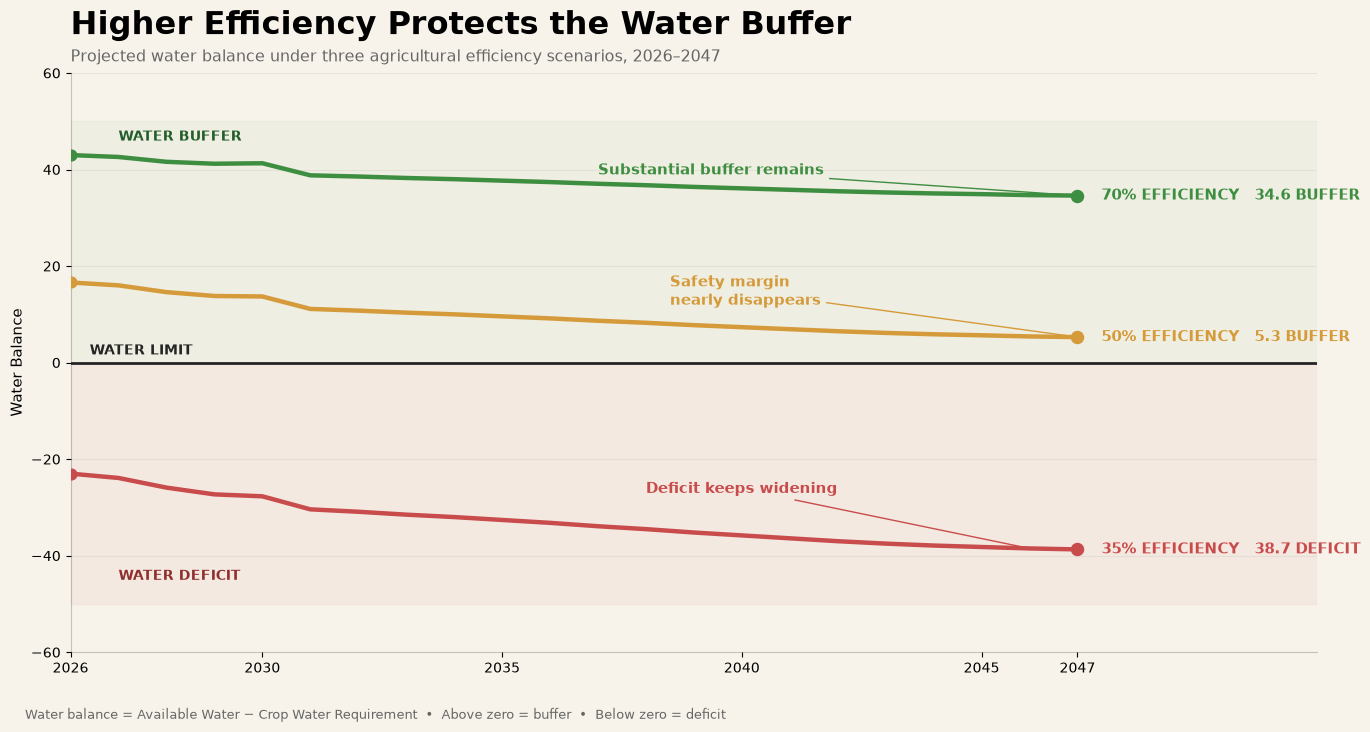

In [3]:
# ============================================================
# SUPPORTING LINE CHART
# WATER BALANCE THROUGH TIME
# ============================================================

import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. COLORS
# ------------------------------------------------------------

COLOR_35 = "#C94C4C"
COLOR_50 = "#D59A3A"
COLOR_70 = "#3E8E41"

COLOR_ZERO = "#252525"
COLOR_TEXT = "#171717"
COLOR_MUTED = "#666666"
COLOR_GRID = "#D8D5CF"

BACKGROUND = "#F7F3EA"


# ------------------------------------------------------------
# 2. FIGURE
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(15, 8)
)

fig.patch.set_facecolor(BACKGROUND)
ax.set_facecolor(BACKGROUND)


# ------------------------------------------------------------
# 3. SHADE THE TWO MEANINGFUL REGIONS
# ------------------------------------------------------------

# Deficit region
ax.axhspan(
    -50,
    0,
    color=COLOR_35,
    alpha=0.055,
    zorder=0
)

# Buffer region
ax.axhspan(
    0,
    50,
    color=COLOR_70,
    alpha=0.045,
    zorder=0
)


# ------------------------------------------------------------
# 4. ZERO = WATER LIMIT
# ------------------------------------------------------------

ax.axhline(
    0,
    color=COLOR_ZERO,
    linewidth=2.0,
    zorder=3
)


# ------------------------------------------------------------
# 5. WATER BALANCE LINES
# ------------------------------------------------------------

ax.plot(
    data["Year"],
    data["Balance_35"],
    color=COLOR_35,
    linewidth=3.2,
    zorder=5
)

ax.plot(
    data["Year"],
    data["Balance_50"],
    color=COLOR_50,
    linewidth=3.2,
    zorder=5
)

ax.plot(
    data["Year"],
    data["Balance_70"],
    color=COLOR_70,
    linewidth=3.2,
    zorder=5
)


# ------------------------------------------------------------
# 6. START + END DOTS
# ------------------------------------------------------------

for column, color in [

    ("Balance_35", COLOR_35),
    ("Balance_50", COLOR_50),
    ("Balance_70", COLOR_70)

]:

    # 2026
    ax.scatter(
        data["Year"].iloc[0],
        data[column].iloc[0],
        s=60,
        color=color,
        zorder=6
    )

    # 2047
    ax.scatter(
        data["Year"].iloc[-1],
        data[column].iloc[-1],
        s=75,
        color=color,
        zorder=6
    )


# ------------------------------------------------------------
# 7. DIRECT END LABELS
# ------------------------------------------------------------

last_year = data["Year"].iloc[-1]


end_labels = [

    (
        "Balance_35",
        COLOR_35,
        "35% EFFICIENCY"
    ),

    (
        "Balance_50",
        COLOR_50,
        "50% EFFICIENCY"
    ),

    (
        "Balance_70",
        COLOR_70,
        "70% EFFICIENCY"
    )

]


for column, color, label in end_labels:

    value = data[column].iloc[-1]

    status = (
        "DEFICIT"
        if value < 0
        else "BUFFER"
    )

    ax.text(

        last_year + 0.5,
        value,

        f"{label}   {abs(value):.1f} {status}",

        color=color,

        fontsize=11,
        fontweight="bold",

        va="center"

    )


# ------------------------------------------------------------
# 8. WATER LIMIT LABEL
# ------------------------------------------------------------

ax.text(

    data["Year"].iloc[0] + 0.4,
    1.7,

    "WATER LIMIT",

    fontsize=10,
    fontweight="bold",

    color=COLOR_ZERO

)


# ------------------------------------------------------------
# 9. REGION LABELS
# ------------------------------------------------------------

ax.text(

    2027,
    -45,

    "WATER DEFICIT",

    color="#8F2F2F",

    fontsize=10,
    fontweight="bold"

)


ax.text(

    2027,
    46,

    "WATER BUFFER",

    color="#245F2B",

    fontsize=10,
    fontweight="bold"

)


# ------------------------------------------------------------
# 10. STORY ANNOTATIONS
# ------------------------------------------------------------

# 35%
ax.annotate(

    "Deficit keeps widening",

    xy=(
        last_year - 1,
        data["Balance_35"].iloc[-2]
    ),

    xytext=(
        2038,
        -27
    ),

    fontsize=11,
    fontweight="bold",

    color=COLOR_35,

    arrowprops=dict(
        arrowstyle="-",
        color=COLOR_35,
        linewidth=1
    )

)


# 50%
ax.annotate(

    "Safety margin\nnearly disappears",

    xy=(
        last_year,
        data["Balance_50"].iloc[-1]
    ),

    xytext=(
        2038.5,
        12
    ),

    fontsize=11,
    fontweight="bold",

    color=COLOR_50,

    arrowprops=dict(
        arrowstyle="-",
        color=COLOR_50,
        linewidth=1
    )

)


# 70%
ax.annotate(

    "Substantial buffer remains",

    xy=(
        last_year,
        data["Balance_70"].iloc[-1]
    ),

    xytext=(
        2037,
        39
    ),

    fontsize=11,
    fontweight="bold",

    color=COLOR_70,

    arrowprops=dict(
        arrowstyle="-",
        color=COLOR_70,
        linewidth=1
    )

)


# ------------------------------------------------------------
# 11. TITLE
# ------------------------------------------------------------

ax.set_title(

    "Higher Efficiency Protects the Water Buffer",

    loc="left",

    fontsize=23,
    fontweight="bold",

    pad=28

)


# ------------------------------------------------------------
# 12. SUBTITLE
# ------------------------------------------------------------

ax.text(

    0,
    1.02,

    "Projected water balance under three agricultural efficiency scenarios, 2026–2047",

    transform=ax.transAxes,

    fontsize=11.5,

    color=COLOR_MUTED

)


# ------------------------------------------------------------
# 13. AXES
# ------------------------------------------------------------

ax.set_ylabel(
    "Water Balance",
    fontsize=11
)


ax.set_xlabel(
    "",
    fontsize=11
)


ax.set_xlim(
    data["Year"].min(),
    data["Year"].max() + 5
)


# Symmetrical axis around zero
max_balance = max(

    abs(data["Balance_35"]).max(),
    abs(data["Balance_50"]).max(),
    abs(data["Balance_70"]).max()

)


limit = (
    int(max_balance / 10) + 2
) * 10


ax.set_ylim(
    -limit,
    limit
)


# ------------------------------------------------------------
# 14. X TICKS
# ------------------------------------------------------------

important_years = [

    2026,
    2030,
    2035,
    2040,
    2045,
    2047

]


ax.set_xticks(
    important_years
)


# ------------------------------------------------------------
# 15. GRID
# ------------------------------------------------------------

ax.grid(

    axis="y",

    color=COLOR_GRID,

    linewidth=0.8,

    alpha=0.55

)


ax.set_axisbelow(True)


# ------------------------------------------------------------
# 16. REMOVE CLUTTER
# ------------------------------------------------------------

ax.spines["top"].set_visible(False)

ax.spines["right"].set_visible(False)

ax.spines["left"].set_alpha(0.2)

ax.spines["bottom"].set_alpha(0.2)


ax.tick_params(
    axis="both",
    labelsize=10
)


# ------------------------------------------------------------
# 17. EXPLANATORY FOOTNOTE
# ------------------------------------------------------------

fig.text(

    0.07,
    0.035,

    "Water balance = Available Water − Crop Water Requirement  •  "
    "Above zero = buffer  •  Below zero = deficit",

    fontsize=9.5,

    color=COLOR_MUTED

)


# ------------------------------------------------------------
# 18. LAYOUT
# ------------------------------------------------------------

plt.tight_layout(

    rect=[
        0.05,
        0.07,
        0.98,
        0.94
    ]

)


# ------------------------------------------------------------
# 19. EXPORT
# ------------------------------------------------------------

plt.savefig(

    "crop_water_balance_trend.png",

    dpi=300,

    bbox_inches="tight",

    facecolor=fig.get_facecolor()

)


plt.savefig(

    "crop_water_balance_trend.pdf",

    bbox_inches="tight",

    facecolor=fig.get_facecolor()

)


plt.show()

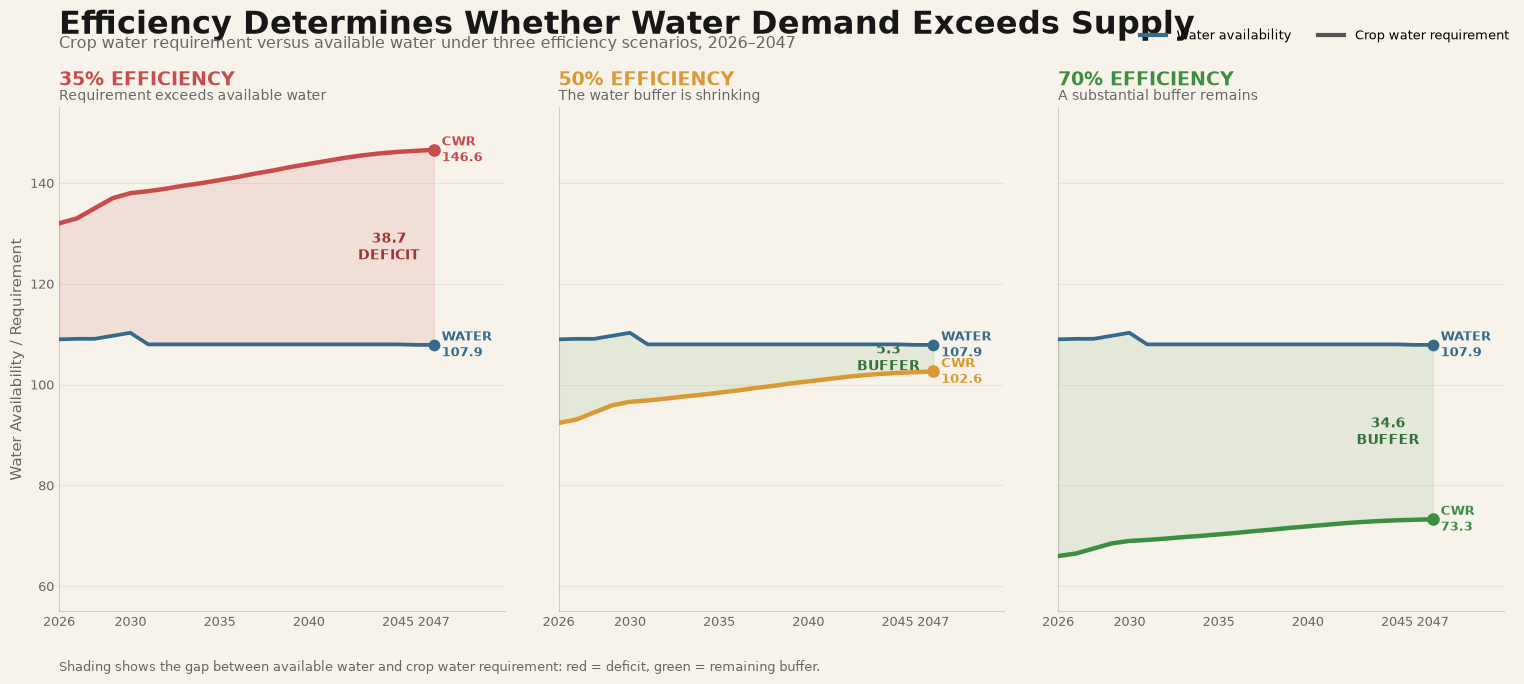

In [5]:
# ============================================================
# SMALL MULTIPLES
# WATER AVAILABILITY vs CROP WATER REQUIREMENT
# ============================================================

import matplotlib.pyplot as plt
import numpy as np


# ============================================================
# 1. STYLE
# ============================================================

BACKGROUND = "#F7F3EA"

COLOR_WATER = "#356A8A"

COLOR_35 = "#C94C4C"
COLOR_50 = "#D99A35"
COLOR_70 = "#3E8E41"

COLOR_TEXT = "#171717"
COLOR_MUTED = "#666666"
COLOR_GRID = "#D8D5CF"


# ============================================================
# 2. PANEL CONFIGURATION
# ============================================================

PANELS = [

    {
        "column": "CWR_35",
        "title": "35% EFFICIENCY",
        "color": COLOR_35,
        "message": "Requirement exceeds available water"
    },

    {
        "column": "CWR_50",
        "title": "50% EFFICIENCY",
        "color": COLOR_50,
        "message": "The water buffer is shrinking"
    },

    {
        "column": "CWR_70",
        "title": "70% EFFICIENCY",
        "color": COLOR_70,
        "message": "A substantial buffer remains"
    }

]


# ============================================================
# 3. COMMON Y-AXIS
# ============================================================

all_values = np.concatenate([

    data["Water"].to_numpy(),

    data["CWR_35"].to_numpy(),

    data["CWR_50"].to_numpy(),

    data["CWR_70"].to_numpy()

])


Y_MIN = (
    np.floor(
        all_values.min() / 10
    ) * 10
) - 5


Y_MAX = (
    np.ceil(
        all_values.max() / 10
    ) * 10
) + 5


# ============================================================
# 4. CREATE SMALL MULTIPLES
# ============================================================

fig, axes = plt.subplots(

    nrows=1,
    ncols=3,

    figsize=(17, 7),

    sharex=True,
    sharey=True

)


fig.patch.set_facecolor(
    BACKGROUND
)


# ============================================================
# 5. DRAW EACH PANEL
# ============================================================

for ax, panel in zip(
    axes,
    PANELS
):


    # --------------------------------------------------------
    # Data
    # --------------------------------------------------------

    years = data["Year"]

    water = data["Water"]

    requirement = data[
        panel["column"]
    ]


    scenario_color = panel[
        "color"
    ]


    ax.set_facecolor(
        BACKGROUND
    )


    # ========================================================
    # SHADE GAP BETWEEN WATER AND REQUIREMENT
    # ========================================================

    # Deficit
    ax.fill_between(

        years,

        water,

        requirement,

        where=(
            requirement > water
        ),

        interpolate=True,

        color="#C94C4C",

        alpha=0.12,

        zorder=1

    )


    # Buffer
    ax.fill_between(

        years,

        requirement,

        water,

        where=(
            requirement <= water
        ),

        interpolate=True,

        color="#3E8E41",

        alpha=0.10,

        zorder=1

    )


    # ========================================================
    # WATER AVAILABILITY
    # ========================================================

    ax.plot(

        years,

        water,

        color=COLOR_WATER,

        linewidth=2.7,

        zorder=4

    )


    # ========================================================
    # CROP WATER REQUIREMENT
    # ========================================================

    ax.plot(

        years,

        requirement,

        color=scenario_color,

        linewidth=3.2,

        zorder=5

    )


    # ========================================================
    # END DOTS
    # ========================================================

    ax.scatter(

        years.iloc[-1],

        water.iloc[-1],

        s=55,

        color=COLOR_WATER,

        zorder=6

    )


    ax.scatter(

        years.iloc[-1],

        requirement.iloc[-1],

        s=65,

        color=scenario_color,

        zorder=6

    )


    # ========================================================
    # PANEL TITLE
    # ========================================================

    ax.set_title(

        panel["title"],

        loc="left",

        fontsize=14,

        fontweight="bold",

        color=scenario_color,

        pad=16

    )


    # ========================================================
    # PANEL STORY
    # ========================================================

    ax.text(

        0,

        1.015,

        panel["message"],

        transform=ax.transAxes,

        fontsize=10,

        color=COLOR_MUTED

    )


    # ========================================================
    # 2047 VALUES
    # ========================================================

    final_water = water.iloc[-1]

    final_requirement = requirement.iloc[-1]


    # Water label
    ax.text(

        years.iloc[-1] + 0.45,

        final_water,

        f"WATER\n{final_water:.1f}",

        color=COLOR_WATER,

        fontsize=9.5,

        fontweight="bold",

        va="center"

    )


    # CWR label
    ax.text(

        years.iloc[-1] + 0.45,

        final_requirement,

        f"CWR\n{final_requirement:.1f}",

        color=scenario_color,

        fontsize=9.5,

        fontweight="bold",

        va="center"

    )


    # ========================================================
    # 2047 GAP
    # ========================================================

    balance = (
        final_water
        -
        final_requirement
    )


    midpoint = (
        final_water
        +
        final_requirement
    ) / 2


    if balance < 0:

        gap_text = (
            f"{abs(balance):.1f}\nDEFICIT"
        )

        gap_color = "#9E3636"

    else:

        gap_text = (
            f"{balance:.1f}\nBUFFER"
        )

        gap_color = "#34723B"


    ax.text(

        2044.5,

        midpoint,

        gap_text,

        ha="center",

        va="center",

        fontsize=10,

        fontweight="bold",

        color=gap_color

    )


    # ========================================================
    # AXES
    # ========================================================

    ax.set_ylim(
        Y_MIN,
        Y_MAX
    )


    ax.set_xlim(

        data["Year"].min(),

        data["Year"].max() + 4

    )


    # ========================================================
    # GRID
    # ========================================================

    ax.grid(

        axis="y",

        color=COLOR_GRID,

        alpha=0.45,

        linewidth=0.8

    )


    ax.set_axisbelow(
        True
    )


    # ========================================================
    # REMOVE CLUTTER
    # ========================================================

    ax.spines[
        "top"
    ].set_visible(
        False
    )


    ax.spines[
        "right"
    ].set_visible(
        False
    )


    ax.spines[
        "left"
    ].set_alpha(
        0.15
    )


    ax.spines[
        "bottom"
    ].set_alpha(
        0.15
    )


    ax.tick_params(

        axis="both",

        length=0,

        labelsize=9,

        colors=COLOR_MUTED

    )


# ============================================================
# 6. X TICKS
# ============================================================

important_years = [

    2026,
    2030,
    2035,
    2040,
    2045,
    2047

]


for ax in axes:

    ax.set_xticks(
        important_years
    )


# ============================================================
# 7. Y AXIS
# ============================================================

axes[0].set_ylabel(

    "Water Availability / Requirement",

    fontsize=10.5,

    color=COLOR_MUTED

)


# ============================================================
# 8. MAIN TITLE
# ============================================================

fig.suptitle(

    "Efficiency Determines Whether Water Demand Exceeds Supply",

    x=0.07,

    y=0.98,

    ha="left",

    fontsize=23,

    fontweight="bold",

    color=COLOR_TEXT

)


# ============================================================
# 9. SUBTITLE
# ============================================================

fig.text(

    0.07,

    0.925,

    "Crop water requirement versus available water under three efficiency scenarios, 2026–2047",

    fontsize=11.5,

    color=COLOR_MUTED

)


# ============================================================
# 10. LEGEND — ONE LEGEND ONLY
# ============================================================

from matplotlib.lines import Line2D


legend_items = [

    Line2D(

        [0],
        [0],

        color=COLOR_WATER,

        linewidth=3,

        label="Water availability"

    ),

    Line2D(

        [0],
        [0],

        color="#555555",

        linewidth=3,

        label="Crop water requirement"

    )

]


fig.legend(

    handles=legend_items,

    loc="upper right",

    bbox_to_anchor=(
        0.93,
        0.97
    ),

    frameon=False,

    ncol=2,

    fontsize=9.5

)


# ============================================================
# 11. FOOTNOTE
# ============================================================

fig.text(

    0.07,

    0.035,

    "Shading shows the gap between available water and crop water requirement: "
    "red = deficit, green = remaining buffer.",

    fontsize=9,

    color=COLOR_MUTED

)


# ============================================================
# 12. LAYOUT
# ============================================================

plt.subplots_adjust(

    left=0.07,

    right=0.92,

    top=0.84,

    bottom=0.12,

    wspace=0.12

)


# ============================================================
# 13. EXPORT
# ============================================================

plt.savefig(

    "crop_water_small_multiples_timeseries.png",

    dpi=300,

    bbox_inches="tight",

    facecolor=fig.get_facecolor()

)


plt.savefig(

    "crop_water_small_multiples_timeseries.pdf",

    bbox_inches="tight",

    facecolor=fig.get_facecolor()

)


plt.show()